# Data-Driven Retail Intelligence: Sales Analysis and Customer Behaviour

## 1. Data Loading and Initial Inspection

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("../data/Online Retail.xlsx")

print(df.shape)

(541909, 8)


In [2]:
df_clean = df.copy()

In [3]:
print("Raw data:", df.shape)
print("Working data:", df_clean.shape)

Raw data: (541909, 8)
Working data: (541909, 8)


In [4]:
duplicate_count = df_clean.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

Number of exact duplicate rows: 5268


In [5]:
duplicate_rows = df_clean[df_clean.duplicated(keep=False)]

duplicate_rows.head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [6]:
df_clean = df_clean.drop_duplicates().copy()
print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Shape after removing duplicates: (536641, 8)
Remaining duplicate rows: 0


## 2. Missing-Value Investigation

In [7]:
# missing value inspection starts from here 
missing_values = df_clean.isnull().sum()

print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [8]:
missing_description = df_clean[
    df_clean['Description'].isna()
]

missing_description.head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [9]:
print("Price distribution:")
print(missing_description['UnitPrice'].value_counts())

print("\nQuantity statistics:")
print(missing_description['Quantity'].describe())

print("\nQuantity categories:")
print("Positive:", (missing_description['Quantity'] > 0).sum())
print("Negative:", (missing_description['Quantity'] < 0).sum())
print("Zero:", (missing_description['Quantity'] == 0).sum())

print("\nCustomer IDs available:",
      missing_description['CustomerID'].notna().sum())

Price distribution:
UnitPrice
0.0    1454
Name: count, dtype: int64

Quantity statistics:
count    1454.000000
mean       -9.359697
std       243.238758
min     -3667.000000
25%       -24.000000
50%        -3.000000
75%         4.000000
max      5568.000000
Name: Quantity, dtype: float64

Quantity categories:
Positive: 592
Negative: 862
Zero: 0

Customer IDs available: 0


In [10]:
print("Unique StockCodes:",
      missing_description['StockCode'].nunique())

print("\nMost common StockCodes:")
print(
    missing_description['StockCode']
    .value_counts()
    .head(20)
)

Unique StockCodes: 960

Most common StockCodes:
StockCode
35965     10
23084     10
22084      9
22451      6
22501      5
21784      5
21033      5
21067      5
23348      5
22866      5
22034      4
84944      4
22114      4
85049D     4
21429      4
79321      4
82583      4
22139      4
71477      4
22444      4
Name: count, dtype: int64


Missing Description — Preprocessing Decision

A total of 1,454 records have missing product descriptions. Investigation showed that all
of these records have a UnitPrice of 0 and a missing CustomerID. Their quantities include
both positive and negative values, and they correspond to 960 unique StockCodes.

Since the available information is insufficient to reliably reconstruct the missing product
descriptions, the records are retained in the cleaned working dataset rather than being
artificially imputed or immediately deleted.

However, these records will not be treated as ordinary product sales in downstream
customer-level and product-sales analysis where a valid customer and positive-priced
transaction are required.

In [12]:
customer_missing_pct = (
    df_clean['CustomerID'].isna().mean() * 100
)

print(f"Missing CustomerID: {customer_missing_pct:.2f}%")

Missing CustomerID: 25.16%


In [13]:
missing_customer = df_clean[
    df_clean['CustomerID'].isna()
]

print("Total missing CustomerID:",
      len(missing_customer))

print(
    "Positive quantity + positive price:",
    (
        (missing_customer['Quantity'] > 0) &
        (missing_customer['UnitPrice'] > 0)
    ).sum()
)

print(
    "Negative quantity:",
    (missing_customer['Quantity'] < 0).sum()
)

print(
    "Zero price:",
    (missing_customer['UnitPrice'] == 0).sum()
)

Total missing CustomerID: 135037
Positive quantity + positive price: 132186
Negative quantity: 1715
Zero price: 2470


Missing CustomerID — Preprocessing Decision

After duplicate removal, 135,037 records (25.16%) have a missing CustomerID.
Further investigation showed that 132,186 of these records have both positive
quantity and positive unit price, indicating that many still contain useful
transaction information.

CustomerID is an identifier and therefore should not be imputed using statistical
methods such as mean or median imputation. The records are therefore retained in
the cleaned dataset.

For customer-level analyses such as RFM analysis and customer segmentation, only
transactions with a known CustomerID will be considered. Analyses that do not
require customer identity may retain appropriate transactions with missing
CustomerID.

## 3. Quantity and Cancellation Investigation

In [15]:
negative_qty = df_clean[
    df_clean['Quantity'] < 0
].copy()

print("Negative quantity records:", len(negative_qty))

Negative quantity records: 10587


In [16]:
negative_qty['InvoiceNo'].astype(str).str.startswith('C').value_counts()

InvoiceNo
True     9251
False    1336
Name: count, dtype: int64

In [17]:
negative_non_c = negative_qty[
    ~negative_qty['InvoiceNo'].astype(str).str.startswith('C')
].copy()

print("Negative quantity without C-prefix:",
      len(negative_non_c))

Negative quantity without C-prefix: 1336


In [18]:
negative_non_c[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'CustomerID', 'Country']
].head(30)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,0.0,NaN,United Kingdom


In [19]:
print("UnitPrice:")
print(negative_non_c['UnitPrice'].value_counts())

print("\nDescription available:")
print(negative_non_c['Description'].notna().sum())

print("\nCustomerID available:")
print(negative_non_c['CustomerID'].notna().sum())

print("\nCountries:")
print(negative_non_c['Country'].value_counts())

UnitPrice:
UnitPrice
0.0    1336
Name: count, dtype: int64

Description available:
474

CustomerID available:
0

Countries:
Country
United Kingdom    1336
Name: count, dtype: int64


In [20]:
negative_non_c[
    negative_non_c['Description'].notna()
]['Description'].value_counts().head(40)

Description
check                                  120
damages                                 45
damaged                                 42
?                                       41
sold as set on dotcom                   20
Damaged                                 14
thrown away                              9
Unsaleable, destroyed.                   9
??                                       7
wet damaged                              5
damages?                                 5
ebay                                     5
smashed                                  4
missing                                  3
wet pallet                               3
CHECK                                    3
sold as 1                                2
incorrect stock entry.                   2
crushed                                  2
adjustment                               2
wet/rusty                                2
reverse 21/5/10 adjustment               2
?missing                                 2

### Negative Quantity Without Cancellation Prefix — Preprocessing Decision

There are 1,336 records with negative quantities but without a `C` invoice prefix.
Investigation showed that all 1,336 records have a UnitPrice of 0 and no CustomerID.
All are associated with the United Kingdom.

Among the 1,336 records, 474 contain descriptions. Common descriptions include
"check", "damages", "damaged", "thrown away", "Unsaleable, destroyed.",
"incorrect stock entry", and "adjustment". These observations indicate that this
group represents stock-related adjustments or other non-sales records rather than
ordinary customer purchases.

These records are therefore retained in the working dataset for traceability, but
will be excluded from the standard sales transaction dataset.

In [22]:
cancellation_df = negative_qty[
    negative_qty['InvoiceNo'].astype(str).str.startswith('C')
].copy()

print("C-prefix negative records:", len(cancellation_df))

cancellation_df[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'CustomerID', 'Country']
].head(20)

C-prefix negative records: 9251


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,17897.0,United Kingdom


In [23]:
print("Total C-prefix records:", len(cancellation_df))

print("\nCustomerID available:")
print(cancellation_df['CustomerID'].notna().sum())

print("\nUnitPrice = 0:")
print((cancellation_df['UnitPrice'] == 0).sum())

print("\nDescription available:")
print(cancellation_df['Description'].notna().sum())

print("\nCountries:")
print(cancellation_df['Country'].nunique())

Total C-prefix records: 9251

CustomerID available:
8872

UnitPrice = 0:
0

Description available:
9251

Countries:
30


### Negative Quantity and Cancellation — Preprocessing Decision

After duplicate removal, 10,587 records have negative quantities. These records were
not removed globally because negative quantities can represent meaningful business
events such as cancellations, returns, or stock adjustments.

A total of 9,251 negative-quantity records have an invoice number beginning with `C`.
All 9,251 have a non-zero UnitPrice and a non-missing Description, while 8,872 have
a CustomerID. These records are treated as cancellation/return-type transactions and
are retained so that their effect can be incorporated into sales analysis.

The remaining 1,336 negative-quantity records do not have a `C` prefix. All have
UnitPrice = 0 and no CustomerID. Their descriptions, where available, frequently
refer to stock checks, damage, disposal, missing stock, or adjustments. These are
retained for traceability but will be excluded from the standard sales transaction
dataset.

## 4. Price Anomalies and Revenue Feature Engineering

In [25]:
nonpositive_price = df_clean[
    df_clean['UnitPrice'] <= 0
].copy()

print("Non-positive price records:",
      len(nonpositive_price))

Non-positive price records: 2512


In [26]:
print("Zero-price records:",
      (df_clean['UnitPrice'] == 0).sum())

print("Negative-price records:",
      (df_clean['UnitPrice'] < 0).sum())

Zero-price records: 2510
Negative-price records: 2


In [27]:
zero_price = df_clean[
    df_clean['UnitPrice'] == 0
].copy()

print("Zero-price records:", len(zero_price))

Zero-price records: 2510


In [28]:
zero_price['Description'].value_counts(dropna=False).head(30)

Description
NaN                                1454
check                               159
?                                    47
damages                              45
damaged                              43
found                                25
sold as set on dotcom                20
adjustment                           16
Damaged                              14
thrown away                           9
FRENCH BLUE METAL DOOR SIGN 1         9
Unsaleable, destroyed.                9
Found                                 8
amazon                                8
FRENCH BLUE METAL DOOR SIGN 8         8
Amazon                                7
RECIPE BOX PANTRY YELLOW DESIGN       7
FRENCH BLUE METAL DOOR SIGN 3         7
OWL DOORSTOP                          7
??                                    7
FRENCH BLUE METAL DOOR SIGN No        7
FRENCH BLUE METAL DOOR SIGN 4         7
FRENCH BLUE METAL DOOR SIGN 5         6
FRENCH BLUE METAL DOOR SIGN 7         6
dotcom                      

In [29]:
print("CustomerID available:",
      zero_price['CustomerID'].notna().sum())

print("Positive quantity:",
      (zero_price['Quantity'] > 0).sum())

print("Negative quantity:",
      (zero_price['Quantity'] < 0).sum())

print("C-prefix invoices:",
      zero_price['InvoiceNo'].astype(str).str.startswith('C').sum())

CustomerID available: 40
Positive quantity: 1174
Negative quantity: 1336
C-prefix invoices: 0


In [30]:
zero_price_customer = zero_price[
    zero_price['CustomerID'].notna()
].copy()

zero_price_customer[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'CustomerID', 'Country']
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,0.0,14410.0,United Kingdom


### Zero-Price Transactions — Preprocessing Decision

After duplicate removal, 2,510 records have UnitPrice = 0. Investigation showed that
these records include both stock-related descriptions and identifiable product
transactions. There are 1,174 records with positive quantities and 1,336 with negative
quantities. Only 40 records have a CustomerID.

The zero-price records are therefore retained in the cleaned working dataset rather
than being treated as universally erroneous. However, because they contribute zero
monetary revenue, they will be excluded from the standard monetary sales dataset
used for revenue-based analysis. They may be examined separately for quantity-based
or operational analysis.

In [32]:
negative_price = df_clean[
    df_clean['UnitPrice'] < 0
].copy()

negative_price[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'CustomerID', 'Country']
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom


### Negative UnitPrice — Preprocessing Decision

Only two records have a negative UnitPrice. Both have StockCode `B` and the
description `Adjust bad debt`, with a quantity of 1, no CustomerID, and a
UnitPrice of -11062.06.

These records represent accounting/bad-debt adjustments rather than ordinary
product sales. They are therefore retained in the cleaned working dataset for
traceability but excluded from the standard sales transaction dataset and
customer/product sales analysis.

In [34]:
df_clean['Revenue'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

In [35]:
df_clean[
    ['Quantity', 'UnitPrice', 'Revenue']
].head(10)

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [36]:
df_clean['Revenue'].describe()

count    536641.000000
mean         18.123861
std         380.656263
min     -168469.600000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: Revenue, dtype: float64

In [37]:
print("Positive revenue:",
      (df_clean['Revenue'] > 0).sum())

print("Zero revenue:",
      (df_clean['Revenue'] == 0).sum())

print("Negative revenue:",
      (df_clean['Revenue'] < 0).sum())

Positive revenue: 524878
Zero revenue: 2510
Negative revenue: 9253


In [38]:
df_clean['IsCancellationInvoice'] = (
    df_clean['InvoiceNo']
    .astype(str)
    .str.startswith('C')
)

print(df_clean['IsCancellationInvoice'].value_counts())

IsCancellationInvoice
False    527390
True       9251
Name: count, dtype: int64


In [39]:
print("C-prefix records with negative quantity:",
      (
          df_clean['IsCancellationInvoice'] &
          (df_clean['Quantity'] < 0)
      ).sum())

print("C-prefix records with non-negative quantity:",
      (
          df_clean['IsCancellationInvoice'] &
          (df_clean['Quantity'] >= 0)
      ).sum())

C-prefix records with negative quantity: 9251
C-prefix records with non-negative quantity: 0


In [40]:
negative_price = df_clean[df_clean['UnitPrice'] < 0]

negative_price[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'CustomerID', 'Country']
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom


In [41]:
df_clean['IsBadDebtAdjustment'] = (
    df_clean['Description']
    .eq('Adjust bad debt')
)

print(df_clean['IsBadDebtAdjustment'].value_counts())

IsBadDebtAdjustment
False    536638
True          3
Name: count, dtype: int64


In [42]:
df_clean.loc[
    df_clean['IsBadDebtAdjustment'],
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'CustomerID', 'Country']
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom


In [43]:
df_clean['IsZeroPrice'] = df_clean['UnitPrice'] == 0

print(df_clean['IsZeroPrice'].value_counts())

IsZeroPrice
False    534131
True       2510
Name: count, dtype: int64


In [44]:
df_clean[df_clean['IsZeroPrice']]['Quantity'].value_counts().sort_index()

Quantity
-9600     2
-9058     1
-5368     1
-4830     1
-3667     1
         ..
 3000     1
 3100     1
 4000     1
 5568     1
 12540    1
Name: count, Length: 426, dtype: int64

In [45]:
print("Negative UnitPrice records:",
      (df_clean['UnitPrice'] < 0).sum())

print("Bad-debt adjustment records:",
      df_clean['IsBadDebtAdjustment'].sum())

Negative UnitPrice records: 2
Bad-debt adjustment records: 3


## 5. Build the Standard-Sales and Customer Datasets

In [46]:
df_sales = df_clean[
    (~df_clean['IsCancellationInvoice']) &
    (~df_clean['IsBadDebtAdjustment']) &
    (~df_clean['IsZeroPrice']) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Cleaned dataset shape:", df_clean.shape)
print("Standard sales dataset shape:", df_sales.shape)


Cleaned dataset shape: (536641, 12)
Standard sales dataset shape: (524877, 12)


In [47]:
print("Cancellation invoices:",
      df_sales['IsCancellationInvoice'].sum())

print("Bad-debt adjustments:",
      df_sales['IsBadDebtAdjustment'].sum())

print("Zero-price records:",
      df_sales['IsZeroPrice'].sum())

print("Negative UnitPrice records:",
      (df_sales['UnitPrice'] < 0).sum())

print("Non-positive UnitPrice records:",
      (df_sales['UnitPrice'] <= 0).sum())

Cancellation invoices: 0
Bad-debt adjustments: 0
Zero-price records: 0
Negative UnitPrice records: 0
Non-positive UnitPrice records: 0


In [48]:
missing_sales = df_sales.isnull().sum()

print(missing_sales[missing_sales > 0])

CustomerID    132185
dtype: int64


In [49]:
missing_customer_count = df_sales['CustomerID'].isnull().sum()
total_sales_records = len(df_sales)

missing_customer_percentage = (
    missing_customer_count / total_sales_records
) * 100

print("Missing CustomerID:", missing_customer_count)
print("Total sales records:", total_sales_records)
print(f"Missing CustomerID percentage: {missing_customer_percentage:.2f}%")

Missing CustomerID: 132185
Total sales records: 524877
Missing CustomerID percentage: 25.18%


In [50]:
df_customer = df_sales[
    df_sales['CustomerID'].notna()
].copy()

print("Sales records:", len(df_sales))
print("Records with CustomerID:", len(df_customer))
print("Unique customers:", df_customer['CustomerID'].nunique())
print("Missing CustomerID:", df_customer['CustomerID'].isnull().sum())

Sales records: 524877
Records with CustomerID: 392692
Unique customers: 4338
Missing CustomerID: 0


In [51]:
print("Negative quantities:",
      (df_customer['Quantity'] < 0).sum())

print("Zero quantities:",
      (df_customer['Quantity'] == 0).sum())

print("Positive quantities:",
      (df_customer['Quantity'] > 0).sum())

Negative quantities: 0
Zero quantities: 0
Positive quantities: 392692


In [52]:
print(df_customer['Quantity'].describe())

count    392692.000000
mean         13.119702
std         180.492832
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64


In [53]:
df_customer.nlargest(
    10, 'Quantity'
)[[
    'InvoiceNo',
    'StockCode',
    'Description',
    'Quantity',
    'UnitPrice',
    'Revenue',
    'CustomerID',
    'Country'
]]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00,13135.0,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,18087.0,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16,14609.0,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00,16308.0,United Kingdom
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40,16754.0,United Kingdom


In [54]:
extreme_sales = df_customer[
    df_customer['Quantity'] > 50000
]

extreme_sales[[
    'InvoiceNo',
    'InvoiceDate',
    'StockCode',
    'Description',
    'Quantity',
    'UnitPrice',
    'Revenue',
    'CustomerID',
    'Country'
]]

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID,Country
61619,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346.0,United Kingdom
540421,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0,United Kingdom


In [55]:
extreme_customer_ids = [12346, 16446]

df_customer[
    df_customer['CustomerID'].isin(extreme_customer_ids)
].sort_values(
    ['CustomerID', 'InvoiceDate']
)[[
    'InvoiceNo',
    'InvoiceDate',
    'Description',
    'Quantity',
    'UnitPrice',
    'Revenue',
    'CustomerID'
]]

,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,Revenue,CustomerID
61619,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0
194354,553573,2011-05-18 09:52:00,PANTRY SCRUBBING BRUSH,1,1.65,1.65,16446.0
194355,553573,2011-05-18 09:52:00,PANTRY PASTRY BRUSH,1,1.25,1.25,16446.0
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0


## 6. Quantity Outlier Investigation

In [56]:
Q1 = df_customer['Quantity'].quantile(0.25)
Q3 = df_customer['Quantity'].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier threshold:", upper_bound)

Q1: 2.0
Q3: 12.0
IQR: 10.0
Upper outlier threshold: 27.0


In [57]:
quantity_outliers = df_customer[
    df_customer['Quantity'] > upper_bound
]

print("Upper outlier threshold:", upper_bound)
print("Quantity outlier records:", len(quantity_outliers))
print(
    "Percentage of records:",
    round(len(quantity_outliers) / len(df_customer) * 100, 2),
    "%"
)

Upper outlier threshold: 27.0
Quantity outlier records: 25616
Percentage of records: 6.52 %


### 📌 Concept Note: Detecting Outliers Using the IQR Method

**Why are we doing this?**

The quantity distribution contains unusually large values. We use the Interquartile Range (IQR) method to identify potential outliers before deciding how to handle them.

**Formula:**

- \(Q1\): 25th percentile
- \(Q3\): 75th percentile
- \(IQR = Q3 - Q1\)
- Upper bound \(= Q3 + 1.5 \times IQR\)

**Our results:**

- Q1 = 2
- Q3 = 12
- IQR = 12 − 2 = 10
- Upper bound = 12 + 1.5 × 10 = **27**

Therefore, quantities greater than 27 are flagged as potential upper outliers.

**Finding:** 25,616 records (6.52% of `df_customer`) exceed this threshold. The maximum quantity is 80,995.

**Decision:** We will not automatically remove or cap these values. Large quantities may represent legitimate bulk purchases. We will investigate unusually large transactions and retain records unless there is sufficient evidence to justify exclusion.

**🎤 Presentation / Viva explanation:**

"I used the Interquartile Range method to detect unusually large quantities. Since Q1 was 2 and Q3 was 12, the IQR was 10, giving an upper outlier threshold of 27 units. Although 6.52% of customer transaction lines exceeded this threshold, I did not automatically remove them because statistical outliers are not necessarily errors. In retail data, they may represent genuine bulk orders. Therefore, I chose to investigate the extreme values before making a preprocessing decision."

**Remember:** IQR flags statistical outliers; it does not prove that a record is incorrect.

In [59]:
quantity_outliers['Quantity'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    25616.000000
mean        99.457409
std        700.585299
min         28.000000
25%         40.000000
50%         48.000000
75%        100.000000
90%        160.000000
95%        250.000000
99%        600.000000
max      80995.000000
Name: Quantity, dtype: float64

In [60]:
extreme_quantity = df_customer[
    df_customer['Quantity'] > 600
]

print("Transactions with quantity > 600:",
      len(extreme_quantity))

print("Percentage of customer transactions:",
      round(len(extreme_quantity) / len(df_customer) * 100, 3),
      "%")

Transactions with quantity > 600: 255
Percentage of customer transactions: 0.065 %


In [61]:
extreme_quantity.nlargest(
    10, 'Quantity'
)[[
    'InvoiceNo',
    'InvoiceDate',
    'Description',
    'Quantity',
    'UnitPrice',
    'Revenue',
    'CustomerID',
    'Country'
]]

,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,Revenue,CustomerID,Country
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,United Kingdom
61619,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,United Kingdom
421632,573008,2011-10-27 12:26:00,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,12901.0,United Kingdom
206121,554868,2011-05-27 10:52:00,SMALL POPCORN HOLDER,4300,0.72,3096.00,13135.0,United Kingdom
97432,544612,2011-02-22 10:43:00,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,18087.0,United Kingdom
270885,560599,2011-07-19 17:04:00,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16,14609.0,United Kingdom
52711,540815,2011-01-11 12:55:00,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
160546,550461,2011-04-18 13:20:00,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
433788,573995,2011-11-02 11:24:00,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00,16308.0,United Kingdom
4945,536830,2010-12-02 17:38:00,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40,16754.0,United Kingdom


### Quantity Outliers — IQR-Based Investigation

The Interquartile Range (IQR) method was used to identify unusually large
transaction quantities. Q1 = 2 and Q3 = 12, giving an IQR of 10 and an
upper outlier threshold of 27 units (Q3 + 1.5 * IQR).

A total of 25,616 records (6.52% of df_customer) exceed this threshold.
Further investigation focused on records with quantities greater than 600,
resulting in 255 records (approximately 0.065% of customer transaction lines).

Inspection of the 10 largest quantities revealed very large transactions,
including 80,995 units of PAPER CRAFT, LITTLE BIRDIE and 74,215 units of
MEDIUM CERAMIC TOP STORAGE JAR. These records have positive unit prices and
calculated revenues, but their large quantities alone do not prove that
the transactions are valid or erroneous.

Decision: Do not automatically delete or cap quantity outliers. Retain them
for now because large quantities may represent legitimate bulk purchases.
Investigate further only when sufficient evidence is available to justify
excluding or adjusting a record.

In [63]:
extreme_quantity.groupby('Description').agg(
    TransactionLines=('Quantity', 'size'),
    TotalQuantity=('Quantity', 'sum'),
    MaxQuantity=('Quantity', 'max')
).sort_values(
    'TotalQuantity', ascending=False
).head(10)

,TransactionLines,TotalQuantity,MaxQuantity
Description,,,
"PAPER CRAFT , LITTLE BIRDIE",1,80995,80995
MEDIUM CERAMIC TOP STORAGE JAR,1,74215,74215
WORLD WAR 2 GLIDERS ASSTD DESIGNS,11,19968,4800
BROCADE RING PURSE,20,14400,720
SMALL CHINESE STYLE SCISSOR,7,11500,3000
POPCORN HOLDER,8,10292,1992
PACK OF 12 LONDON TISSUES,9,8784,1296
RABBIT NIGHT LIGHT,6,8712,2400
RED HARMONICA IN BOX,7,8420,2100


In [64]:
extreme_invoice_ids = [541431, 581483]

df_sales[
    df_sales['InvoiceNo'].isin(extreme_invoice_ids)
][[
    'InvoiceNo',
    'InvoiceDate',
    'StockCode',
    'Description',
    'Quantity',
    'UnitPrice',
    'Revenue',
    'CustomerID'
]].sort_values('InvoiceNo')

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID
61619,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346.0
540421,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0


### Extreme Quantity Investigation — Invoice-Level Check

The two largest quantity records were inspected at invoice level to check
whether additional product lines could provide context for the unusually
large quantities.

Each invoice returned one transaction line in df_sales. This inspection
did not provide additional evidence that either quantity was erroneous.

Decision: Retain both records for now. A large quantity and an isolated
invoice line are not sufficient evidence of invalid data. These transactions
may substantially affect sales totals and averages, so their influence
should be considered when interpreting the results.

## 7. Duplicate and Data-Quality Validation

In [66]:
print(
    "Duplicate invoice-product pairs:",
    df_sales.duplicated(
        subset=['InvoiceNo', 'StockCode', 'Description']
    ).sum()
)

Duplicate invoice-product pairs: 5274


In [67]:
duplicate_pairs = df_sales[
    df_sales.duplicated(
        subset=['InvoiceNo', 'StockCode', 'Description'],
        keep=False
    )
].sort_values(
    ['InvoiceNo', 'StockCode', 'Description']
)

duplicate_pairs[[
    'InvoiceNo',
    'InvoiceDate',
    'StockCode',
    'Description',
    'Quantity',
    'UnitPrice',
    'Revenue',
    'CustomerID'
]].head(20)

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID
113,536381,2010-12-01 09:41:00,71270,PHOTO CLIP LINE,1,1.25,1.25,15311.0
125,536381,2010-12-01 09:41:00,71270,PHOTO CLIP LINE,3,1.25,3.75,15311.0
491,536409,2010-12-01 11:45:00,85116,BLACK CANDELABRA T-LIGHT HOLDER,1,2.10,2.10,17908.0
502,536409,2010-12-01 11:45:00,85116,BLACK CANDELABRA T-LIGHT HOLDER,5,2.10,10.50,17908.0
483,536409,2010-12-01 11:45:00,90199C,5 STRAND GLASS NECKLACE CRYSTAL,3,6.35,19.05,17908.0
498,536409,2010-12-01 11:45:00,90199C,5 STRAND GLASS NECKLACE CRYSTAL,1,6.35,6.35,17908.0
525,536409,2010-12-01 11:45:00,90199C,5 STRAND GLASS NECKLACE CRYSTAL,2,6.35,12.70,17908.0
565,536412,2010-12-01 11:49:00,21448,12 DAISY PEGS IN WOOD BOX,2,1.65,3.30,17920.0
578,536412,2010-12-01 11:49:00,21448,12 DAISY PEGS IN WOOD BOX,1,1.65,1.65,17920.0
561,536412,2010-12-01 11:49:00,21738,COSY SLIPPER SHOES SMALL RED,1,2.95,2.95,17920.0


In [68]:
original_columns = [
    'InvoiceNo',
    'StockCode',
    'Description',
    'Quantity',
    'InvoiceDate',
    'UnitPrice',
    'CustomerID',
    'Country'
]

print(
    "Exact duplicate transaction rows in df_sales:",
    df_sales.duplicated(subset=original_columns).sum()
)

Exact duplicate transaction rows in df_sales: 0


### Duplicate Transaction Validation

After removing exact duplicate rows from the original dataset, we checked
for repeated InvoiceNo–StockCode–Description combinations in df_sales.
A total of 5,274 repeated combinations were identified, but inspection
showed that these can represent separate transaction lines with different
quantities. Repeated invoice-product combinations are therefore not treated
as duplicates by themselves.

A second check across all eight original transaction fields found zero
exact duplicate rows in df_sales.

Decision: Retain the repeated invoice-product combinations because no exact
duplicate transaction rows remain. This prevents the accidental removal
of legitimate transaction lines.

In [70]:
print("Missing InvoiceDate:", df_sales['InvoiceDate'].isna().sum())
print("Earliest transaction:", df_sales['InvoiceDate'].min())
print("Latest transaction:", df_sales['InvoiceDate'].max())

Missing InvoiceDate: 0
Earliest transaction: 2010-12-01 08:26:00
Latest transaction: 2011-12-09 12:50:00


In [71]:
revenue_check = (
    df_sales['Revenue']
    - df_sales['Quantity'] * df_sales['UnitPrice']
)

print("Revenue mismatches:", (revenue_check.abs() > 1e-9).sum())
print("Missing Revenue:", df_sales['Revenue'].isna().sum())

Revenue mismatches: 0
Missing Revenue: 0


In [72]:
print("Unique descriptions:", df_sales['Description'].nunique())

print("\nMost frequent descriptions:")
print(df_sales['Description'].value_counts().head(20))

Unique descriptions: 4025

Most frequent descriptions:
Description
WHITE HANGING HEART T-LIGHT HOLDER    2311
JUMBO BAG RED RETROSPOT               2109
REGENCY CAKESTAND 3 TIER              2007
PARTY BUNTING                         1699
LUNCH BAG RED RETROSPOT               1581
ASSORTED COLOUR BIRD ORNAMENT         1476
SET OF 3 CAKE TINS PANTRY DESIGN      1392
PACK OF 72 RETROSPOT CAKE CASES       1352
LUNCH BAG  BLACK SKULL.               1301
NATURAL SLATE HEART CHALKBOARD        1255
JUMBO BAG PINK POLKADOT               1232
HEART OF WICKER SMALL                 1219
JUMBO STORAGE BAG SUKI                1194
PAPER CHAIN KIT 50'S CHRISTMAS        1184
JUMBO SHOPPER VINTAGE RED PAISLEY     1180
JAM MAKING SET PRINTED                1164
LUNCH BAG SPACEBOY DESIGN             1164
LUNCH BAG CARS BLUE                   1162
SPOTTY BUNTING                        1154
JAM MAKING SET WITH JARS              1133
Name: count, dtype: int64


In [73]:
keywords = [
    'POSTAGE', 'CARRIAGE', 'FEE', 'AMAZON',
    'MANUAL', 'SAMPLE', 'DISCOUNT', 'ADJUST',
    'BANK CHARGES', 'DOTCOM'
]

for keyword in keywords:
    matches = df_sales[
        df_sales['Description'].str.contains(
            keyword, case=False, na=False
        )
    ]

    if not matches.empty:
        print(f"\n--- {keyword} ({len(matches)} rows) ---")
        print(
            matches['Description']
            .value_counts()
            .head(10)
            .to_string()
        )


--- POSTAGE (1832 rows) ---
Description
POSTAGE           1126
DOTCOM POSTAGE     706

--- CARRIAGE (314 rows) ---
Description
CARRIAGE                        141
Next Day Carriage                79
FRENCH CARRIAGE LANTERN          59
BLACK BAROQUE CARRIAGE CLOCK     35

--- FEE (3440 rows) ---
Description
SET OF TEA COFFEE SUGAR TINS PANTRY    471
SET 3 RETROSPOT TEA,COFFEE,SUGAR       434
LONDON BUS COFFEE MUG                  319
QUEENS GUARD COFFEE MUG                274
COFFEE MUG APPLES DESIGN               262
COFFEE MUG CAT + BIRD DESIGN           252
COFFEE MUG PEARS  DESIGN               213
COFFEE MUG DOG + BALL DESIGN           196
RETRO COFFEE MUGS ASSORTED             162
POLKADOT COFFEE CUP & SAUCER PINK      110

--- AMAZON (2 rows) ---
Description
AMAZON FEE    2

--- MANUAL (317 rows) ---
Description
Manual    317

--- SAMPLE (2 rows) ---
Description
SAMPLES    2

--- BANK CHARGES (12 rows) ---
Description
Bank Charges    12

--- DOTCOM (745 rows) ---
Description
DOT

In [74]:
special_descriptions = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'CARRIAGE',
    'Next Day Carriage',
    'AMAZON FEE',
    'Manual',
    'SAMPLES',
    'Bank Charges'
]

special_rows = df_sales[
    df_sales['Description'].isin(special_descriptions)
]

print("Total matching rows:", len(special_rows))

display(
    special_rows[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'Revenue',
         'CustomerID', 'Country']
    ].head(15)
)

Total matching rows: 2385


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID,Country
45,536370,POST,POSTAGE,3,18.00,54.00,12583.0,France
386,536403,POST,POSTAGE,1,15.00,15.00,12791.0,Netherlands
1123,536527,POST,POSTAGE,1,18.00,18.00,12662.0,Germany
1423,536540,C2,CARRIAGE,1,50.00,50.00,14911.0,EIRE
1814,536544,DOT,DOTCOM POSTAGE,1,569.77,569.77,NaN,United Kingdom
2239,536569,M,Manual,1,1.25,1.25,16274.0,United Kingdom
2250,536569,M,Manual,1,18.95,18.95,16274.0,United Kingdom
3041,536592,DOT,DOTCOM POSTAGE,1,607.49,607.49,NaN,United Kingdom
4406,536779,BANK CHARGES,Bank Charges,1,15.00,15.00,15823.0,United Kingdom
5073,536840,POST,POSTAGE,1,18.00,18.00,12738.0,Germany


In [75]:
non_product_descriptions = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'CARRIAGE',
    'Next Day Carriage',
    'AMAZON FEE',
    'Manual',
    'SAMPLES',
    'Bank Charges'
]

special_rows = df_sales[
    df_sales['Description'].isin(non_product_descriptions)
]

print("Rows identified:", len(special_rows))
print("Share of df_sales: {:.2f}%".format(
    len(special_rows) / len(df_sales) * 100
))

print("\nRevenue by description:")
print(
    special_rows.groupby('Description')['Revenue']
    .agg(['count', 'sum'])
    .sort_values('count', ascending=False)
    .round(2)
)

Rows identified: 2385
Share of df_sales: 0.45%

Revenue by description:
                   count        sum
Description                        
POSTAGE             1126   78101.88
DOTCOM POSTAGE       706  206248.77
Manual               317   77752.82
CARRIAGE             141    7051.00
Next Day Carriage     79    1200.00
Bank Charges          12     165.00
AMAZON FEE             2   13761.09
SAMPLES                2      63.05


In [76]:
print("Quantity <= 0:", (df_sales['Quantity'] <= 0).sum())
print("UnitPrice <= 0:", (df_sales['UnitPrice'] <= 0).sum())

print("\nDataset shape:", df_sales.shape)

Quantity <= 0: 0
UnitPrice <= 0: 0

Dataset shape: (524877, 12)


In [77]:
print("Column data types:")
print(df_sales.dtypes)

print("\nMissing values:")
print(df_sales.isna().sum())

Column data types:
InvoiceNo                        object
StockCode                        object
Description                      object
Quantity                          int64
InvoiceDate              datetime64[ns]
UnitPrice                       float64
CustomerID                      float64
Country                          object
Revenue                         float64
IsCancellationInvoice              bool
IsBadDebtAdjustment                bool
IsZeroPrice                        bool
dtype: object

Missing values:
InvoiceNo                     0
StockCode                     0
Description                   0
Quantity                      0
InvoiceDate                   0
UnitPrice                     0
CustomerID               132185
Country                       0
Revenue                       0
IsCancellationInvoice         0
IsBadDebtAdjustment           0
IsZeroPrice                   0
dtype: int64


In [78]:
print("Unique stock codes:", df_sales['StockCode'].nunique())

print("\nMost frequent stock codes:")
print(df_sales['StockCode'].value_counts().head(20))

Unique stock codes: 3921

Most frequent stock codes:
StockCode
85123A    2253
85099B    2109
22423     2007
47566     1699
20725     1582
84879     1476
22197     1418
22720     1392
21212     1352
22383     1306
20727     1301
22457     1255
23203     1242
22386     1232
22469     1219
21931     1194
22086     1184
22411     1180
22961     1164
22382     1164
Name: count, dtype: int64


In [79]:
special_codes = ['POST', 'DOT', 'M', 'C2', 'D', 'B', 'BANK CHARGES', 'AMAZON FEE']

print(
    df_sales[df_sales['StockCode'].isin(special_codes)]
    .groupby(['StockCode', 'Description'])
    .agg(
        Rows=('InvoiceNo', 'size'),
        Revenue=('Revenue', 'sum')
    )
    .sort_values('Rows', ascending=False)
    .round(2)
)

                             Rows    Revenue
StockCode    Description                    
POST         POSTAGE         1126   78101.88
DOT          DOTCOM POSTAGE   706  206248.77
M            Manual           316   77750.27
C2           CARRIAGE         141    7051.00
BANK CHARGES Bank Charges      12     165.00


In [80]:
print("Unique countries:", df_sales['Country'].nunique())

print("\nCountry names:")
print(sorted(df_sales['Country'].unique()))

Unique countries: 38

Country names:
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'EIRE', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'RSA', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'USA', 'United Arab Emirates', 'United Kingdom', 'Unspecified']


In [81]:
checks = {
    "Exact duplicate rows": df_sales.duplicated().sum(),
    "Missing descriptions": df_sales['Description'].isna().sum(),
    "Missing invoice dates": df_sales['InvoiceDate'].isna().sum(),
    "Non-positive quantities": (df_sales['Quantity'] <= 0).sum(),
    "Non-positive unit prices": (df_sales['UnitPrice'] <= 0).sum(),
    "Missing revenue": df_sales['Revenue'].isna().sum(),
    "Revenue mismatches": (
        (df_sales['Revenue'] -
         df_sales['Quantity'] * df_sales['UnitPrice']).abs() > 1e-9
    ).sum()
}

print(pd.Series(checks, name="Count"))
print("\nFinal working dataset shape:", df_sales.shape)

Exact duplicate rows        0
Missing descriptions        0
Missing invoice dates       0
Non-positive quantities     0
Non-positive unit prices    0
Missing revenue             0
Revenue mismatches          0
Name: Count, dtype: int64

Final working dataset shape: (524877, 12)


## 8. Preprocessing Summary and Decisions

# Data Preprocessing — Summary and Decisions

## 1. Dataset Overview
The UCI Online Retail dataset originally contained 541,909 rows and 8 columns.
A working copy, `df_clean`, was created to preserve the original dataset.
After removing 5,268 exact duplicate rows, `df_clean` contained 536,641 rows.

## 2. Missing Values
The original dataset contained 1,454 missing Description values and 135,037
missing CustomerID values after duplicate removal.

Missing descriptions were not imputed with invented product names. The
records with missing descriptions had zero unit prices and were consequently
excluded from the standard-sales dataset.

Missing CustomerID values were retained in `df_sales` because the transactions
can still contribute to overall sales analysis. Rows without CustomerID are
excluded when customer-specific analysis is required.

## 3. Transaction Validation and Filtering
A cancellation flag was created using invoice numbers beginning with `C`.
There were 9,251 such records, which were excluded from `df_sales` but retained
in `df_clean` for traceability.

A bad-debt adjustment flag identified 3 records described as `Adjust bad debt`.
These were excluded from the standard-sales dataset.

A zero-price flag identified 2,510 records. Records with zero prices were
excluded from `df_sales`. The two records with negative unit prices were also
excluded through the positive-price filter.

The standard-sales dataset was created by excluding cancellation invoices,
bad-debt adjustments, zero-price records, and records with non-positive unit
prices. The resulting `df_sales` contains 524,877 rows and 12 columns.

## 4. Revenue Calculation
A Revenue column was calculated as:

Revenue = Quantity × UnitPrice

Validation found zero missing revenue values and zero calculation mismatches
in `df_sales`. Revenue represents transaction-line value, not profit.

## 5. Duplicate and Outlier Decisions
Exact duplicate rows were removed from the working dataset. Repeated
InvoiceNo–StockCode–Description combinations were retained because they may
represent legitimate separate transaction lines. No exact duplicate rows
remained in `df_sales`.

Large quantities were investigated using the IQR method. The upper threshold
was 27 units, and 25,616 customer transaction lines exceeded this threshold.
Further inspection found very large transactions, but quantity alone did not
prove that these records were errors. Quantity outliers were therefore
retained rather than automatically deleted or capped.

## 6. Dates, Data Types, and Categories
`InvoiceDate` was already in datetime format and contained no missing values.
The recorded transaction period runs from 1 December 2010 to 9 December 2011.

Quantity, UnitPrice, and Revenue are numeric columns. The validation dataset
contains 38 distinct country labels. Labels such as `EIRE` and `Unspecified`
were retained as recorded in the source.

## 7. Special Transaction Types
Investigations identified entries such as POSTAGE, DOTCOM POSTAGE, CARRIAGE,
Manual, and Bank Charges. These can represent charges or operational entries
rather than ordinary products.

These records remain in `df_sales` for now. They should be considered
separately when performing product-level analysis, and any further exclusion
should be supported by evidence.

## 8. Final Validation
The following checks passed in `df_sales`:
- Zero exact duplicate rows.
- Zero missing descriptions or invoice dates.
- Zero non-positive quantities or unit prices.
- Zero missing revenue values.
- Zero revenue calculation mismatches.

The resulting `df_sales` is a validated working dataset for exploratory
analysis, subject to further investigation of special transaction types.

## 9. Datasets for Subsequent Analysis
- `df_clean`: cleaned working copy retaining flagged records for traceability.
- `df_sales`: working standard-sales dataset for overall sales analysis.
- `df_customer`: sales records with known CustomerID values for customer-level
  analysis.

Further exploratory analysis will investigate sales trends, product
performance, country-wise sales, and customer behaviour.

## 9. Exploratory Data Analysis

In [83]:
print("Total transaction lines:", len(df_sales))
print("Unique invoices:", df_sales['InvoiceNo'].nunique())
print("Unique products:", df_sales['StockCode'].nunique())
print("Unique countries:", df_sales['Country'].nunique())

print("\nOverall sales statistics:")
print(df_sales[['Quantity', 'UnitPrice', 'Revenue']].describe().round(2))

Total transaction lines: 524877
Unique invoices: 19959
Unique products: 3921
Unique countries: 38

Overall sales statistics:
        Quantity  UnitPrice    Revenue
count  524877.00  524877.00  524877.00
mean       10.62       3.90      20.25
std       156.28      32.71     271.27
min         1.00       0.00       0.00
25%         1.00       1.25       3.90
50%         4.00       2.08       9.92
75%        11.00       4.13      17.70
max     80995.00   13541.33  168469.60


In [84]:
monthly_sales = (
    df_sales
    .set_index('InvoiceDate')
    .resample('MS')['Revenue']
    .sum()
)

print(monthly_sales.round(2))

InvoiceDate
2010-12-01     821452.73
2011-01-01     689811.61
2011-02-01     522545.56
2011-03-01     716215.26
2011-04-01     536968.49
2011-05-01     769296.61
2011-06-01     760547.01
2011-07-01     718076.12
2011-08-01     746779.32
2011-09-01    1056435.19
2011-10-01    1151263.73
2011-11-01    1503866.78
2011-12-01     637790.33
Freq: MS, Name: Revenue, dtype: float64


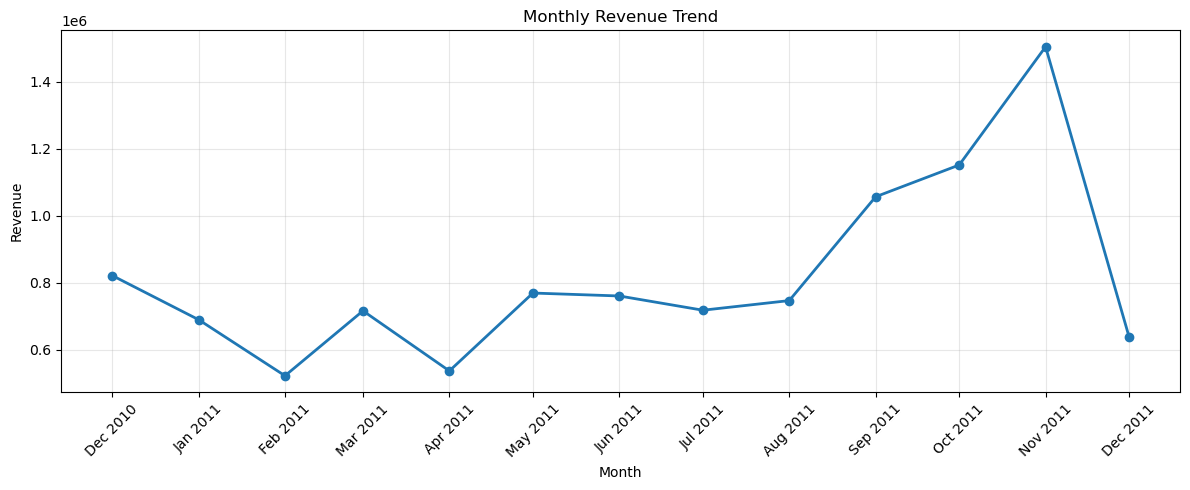

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(monthly_sales.index, monthly_sales.index.strftime('%b %Y'), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [86]:
top_products = (
    df_sales
    .groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products.round(2))

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


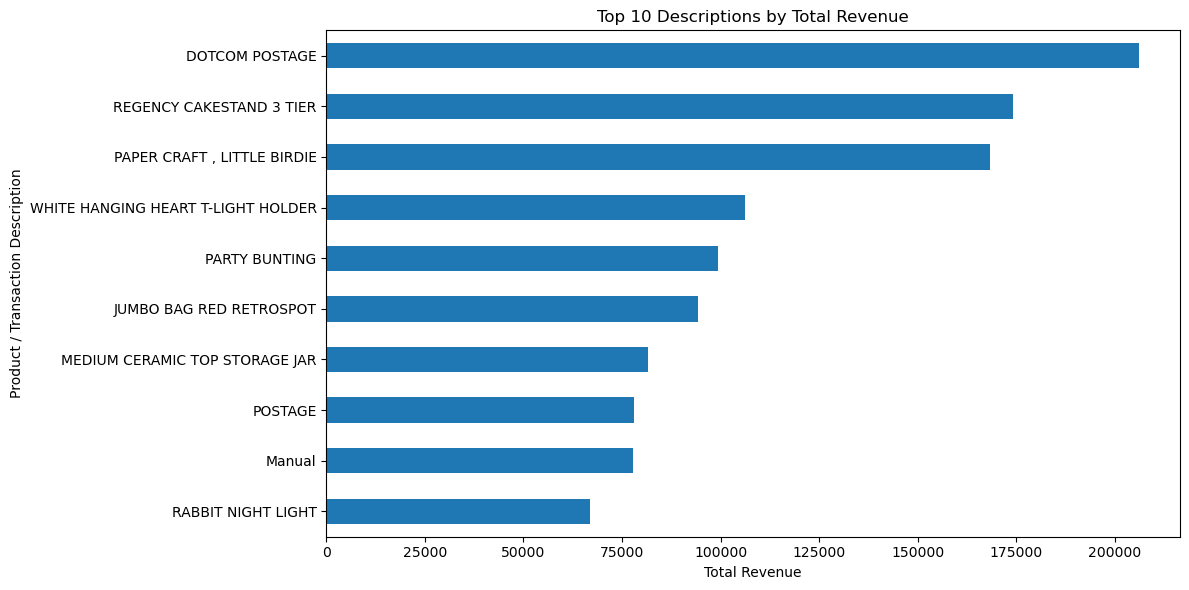

In [87]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Descriptions by Total Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product / Transaction Description')
plt.tight_layout()
plt.show()

In [88]:
top_quantity = (
    df_sales
    .groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_quantity)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


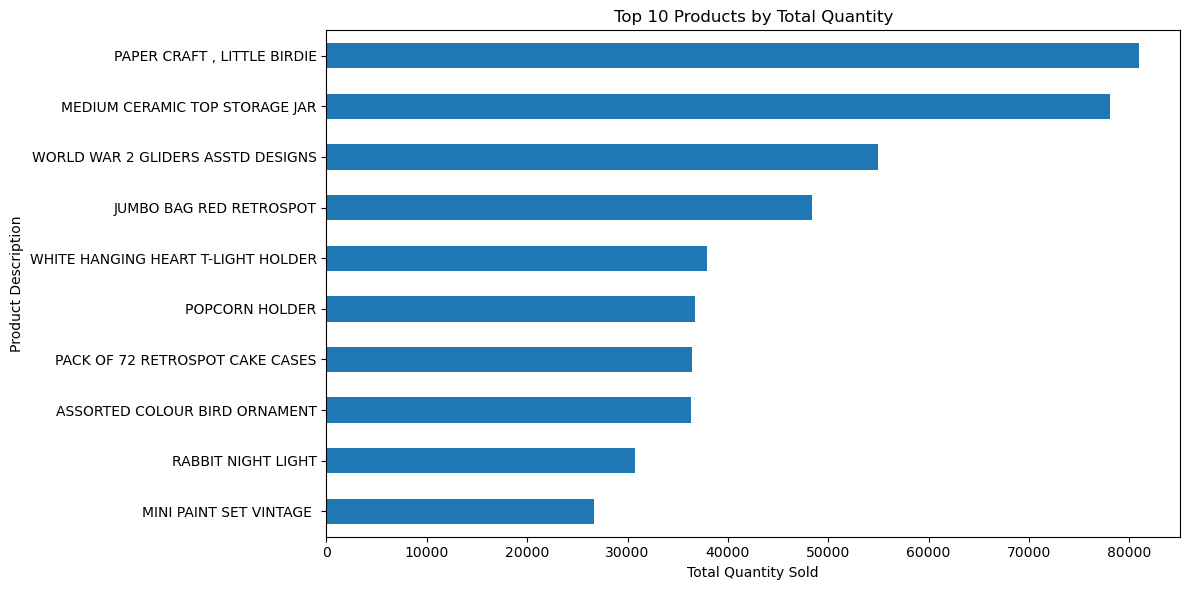

In [89]:
plt.figure(figsize=(12, 6))

top_quantity.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Total Quantity')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

In [90]:
country_sales = (
    df_sales
    .groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

print(country_sales.head(10).round(2))

Country
United Kingdom    8990682.03
Netherlands        285446.34
EIRE               283140.52
Germany            228678.40
France             209625.37
Australia          138453.81
Spain               61558.56
Switzerland         57067.60
Belgium             41196.34
Sweden              38367.83
Name: Revenue, dtype: float64


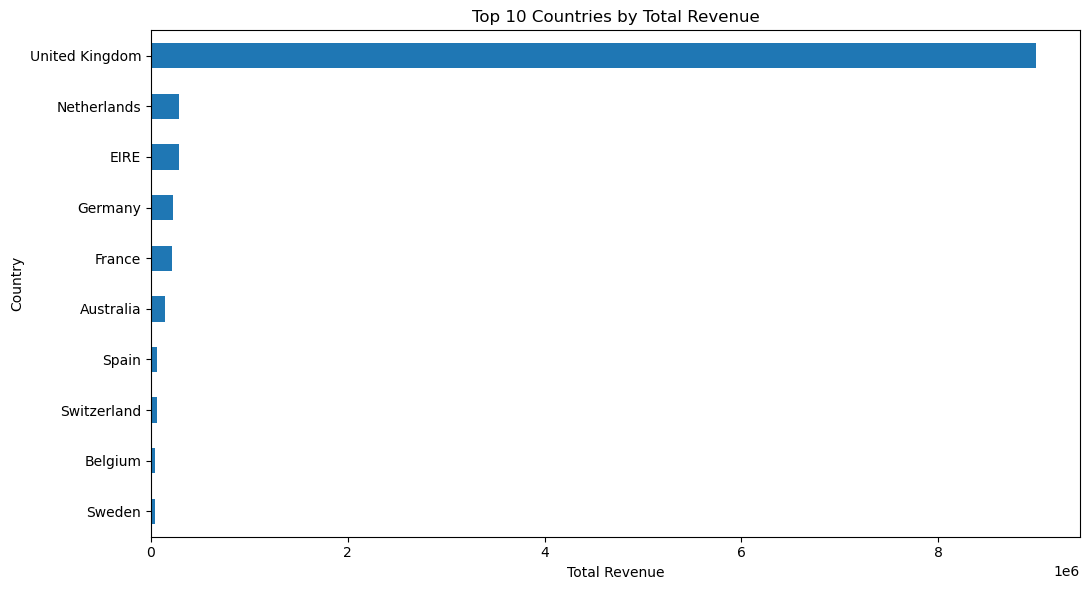

In [91]:
top_countries = country_sales.head(10)

plt.figure(figsize=(11, 6))

top_countries.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Total Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [92]:
country_summary = pd.DataFrame({
    'Revenue': country_sales,
    'RevenueShare_%': (
        country_sales / country_sales.sum() * 100
    )
})

print(country_summary.head(10).round(2))
print("\nTotal recorded revenue:", round(country_sales.sum(), 2))

                   Revenue  RevenueShare_%
Country                                   
United Kingdom  8990682.03           84.57
Netherlands      285446.34            2.69
EIRE             283140.52            2.66
Germany          228678.40            2.15
France           209625.37            1.97
Australia        138453.81            1.30
Spain             61558.56            0.58
Switzerland       57067.60            0.54
Belgium           41196.34            0.39
Sweden            38367.83            0.36

Total recorded revenue: 10631048.74


EXPLORATORY DATA ANALYSIS (EDA) — SUMMARY AND APPROACH

Objective:
Explore the cleaned retail transaction data to understand overall
sales performance, product demand, geographic revenue distribution,
and customer purchasing behaviour.

Dataset used:
df_sales — 524,877 transaction lines containing 19,959 unique
invoice numbers, 3,921 unique stock codes, and 38 country labels.

1. OVERALL SALES STATISTICS
Used pandas descriptive statistics (.describe()) to examine
Quantity, UnitPrice, and Revenue.

Key findings:
- Mean quantity per transaction line: 10.62 units.
- Median quantity: 4 units.
- Mean line revenue: 20.25.
- Median line revenue: 9.92.
- Maximum quantity: 80,995 units.
- Maximum line revenue: 168,469.60.

Interpretation:
Means are higher than medians, suggesting right-skewed
distributions where a small number of large transactions raise
the average. Extreme values require careful interpretation.

2. MONTHLY REVENUE TREND
Set InvoiceDate as the time index and used monthly resampling
(resample('MS')) to sum Revenue for each month.
A line chart was created using Matplotlib to visualize changes
over time.

Key findings:
- November 2011 had the highest monthly revenue: 1,503,866.78.
- February 2011 had the lowest monthly revenue: 522,545.56.
- Revenue increased considerably from August through November.
- December 2011 revenue was 637,790.33, but data ends on
  December 9, so December is an incomplete month.

Interpretation:
Revenue varied over time, with a strong rise toward November.
The incomplete December value should not be compared directly
with complete months. The trend alone does not establish why
revenue increased or prove a seasonal pattern.

3. TOP DESCRIPTIONS BY REVENUE
Grouped records by Description, summed Revenue, sorted in
descending order, and selected the top 10 descriptions.
A horizontal bar chart was created to compare their revenue.

Key findings:
- DOTCOM POSTAGE ranked first at 206,248.77.
- REGENCY CAKESTAND 3 TIER was the highest-ranking ordinary
  product in the top 10, at 174,156.54.
- PAPER CRAFT, LITTLE BIRDIE generated 168,469.60.
- POSTAGE and Manual also appeared in the top 10.

Interpretation:
Revenue rankings include special transaction descriptions,
not just physical products. Therefore, postage and manual
entries must be considered separately in product-level analysis.
The revenue of PAPER CRAFT, LITTLE BIRDIE is strongly affected
by one exceptionally large transaction.

4. TOP DESCRIPTIONS BY TOTAL QUANTITY
Grouped by Description, summed Quantity, sorted in descending
order, and selected the top 10. A horizontal bar chart was used.

Key findings:
- PAPER CRAFT, LITTLE BIRDIE: 80,995 units.
- MEDIUM CERAMIC TOP STORAGE JAR: 78,033 units.
- WORLD WAR 2 GLIDERS ASSTD DESIGNS: 54,951 units.

Interpretation:
The products with the highest quantities are not necessarily
the products with the highest revenue. Quantity measures the
number of units recorded, not the number of purchases or customers.
The top two totals are each dominated by an unusually large
transaction, which must be considered when interpreting demand.

5. COUNTRY-WISE REVENUE ANALYSIS
Grouped records by Country, summed Revenue, and ranked countries
from highest to lowest. A horizontal bar chart was created.
Revenue share was calculated as:

Country Revenue Share (%) =
    Country Revenue / Total Recorded Revenue * 100

Key findings:
- Total recorded revenue: 10,631,048.74.
- United Kingdom revenue: 8,990,682.03.
- United Kingdom revenue share: 84.57%.
- Netherlands: 2.69%; EIRE: 2.66%.
- Germany: 2.15%; France: 1.97%.

Interpretation:
Recorded revenue is highly concentrated in the United Kingdom.
Other countries contribute smaller individual shares.
These figures include retained postage and other special
transaction types, so they represent recorded revenue rather
than product-only revenue.

6. CUSTOMER PURCHASING BEHAVIOUR
Used df_customer, which contains only records with a known
CustomerID. Grouped transactions by CustomerID and calculated:
- TotalInvoices: number of distinct invoices per customer.
- TotalQuantity: total recorded units per customer.
- TotalRevenue: total recorded revenue per customer.

Key findings:
- Unique identified customers: 4,338.
- Mean invoices per customer: 4.27; median: 2.
- Mean customer revenue: 2,048.69; median: 668.57.
- Maximum customer revenue: 280,206.02.
- Customer 14646 had the highest revenue in the current data.
- Customer 14911 had 201 invoices, the highest among the
  10 highest-revenue customers shown.

Interpretation:
The difference between mean and median suggests that customer
purchasing activity and revenue are unevenly distributed.
Frequent purchasing and high monetary value are different
measures and should be analyzed separately.

Customer IDs 16446 and 12346 illustrate how a single unusually
large transaction can inflate customer revenue. These cases
should be interpreted cautiously rather than automatically
treated as consistently high-value customers.

LIMITATIONS AND NEXT STEPS
- EDA is descriptive; observed patterns do not by themselves
  establish causes.
- Extreme quantities may represent bulk purchases, so they
  should not be removed without sufficient evidence.
- Postage, Manual, and other special entries remain in df_sales
  and may affect product and country revenue comparisons.
- Customers with missing CustomerID are excluded from
  customer-specific analysis but retained in df_sales.
- December 2011 is incomplete and requires cautious comparison.

Planned next analyses:
1. Visualize the top 10 customers by revenue.
2. Compare one-time and repeat customers.
3. Investigate customer recency, frequency, and monetary value
   (RFM analysis).
4. Continue with further statistical analysis and visualizations.

Overall approach:
Use pandas for grouping, aggregation, and descriptive statistics;
Matplotlib for visual exploration; and evidence-based interpretation
to identify patterns while acknowledging data limitations.

### 9.1 Customer Behaviour and Customer Value

customer behaviour analysis

In [93]:
customer_summary = (
    df_customer
    .groupby('CustomerID')
    .agg(
        TotalInvoices=('InvoiceNo', 'nunique'),
        TotalQuantity=('Quantity', 'sum'),
        TotalRevenue=('Revenue', 'sum')
    )
)

print("Unique customers:", len(customer_summary))

print("\nCustomer summary statistics:")
print(customer_summary.describe().round(2))

Unique customers: 4338

Customer summary statistics:
       TotalInvoices  TotalQuantity  TotalRevenue
count        4338.00        4338.00       4338.00
mean            4.27        1187.64       2048.69
std             7.70        5043.62       8985.23
min             1.00           1.00          3.75
25%             1.00         159.00        306.48
50%             2.00         378.00        668.57
75%             5.00         989.75       1660.60
max           209.00      196915.00     280206.02


In [94]:
top_customers = (
    customer_summary
    .sort_values('TotalRevenue', ascending=False)
    .head(10)
)

print(top_customers.round(2))

            TotalInvoices  TotalQuantity  TotalRevenue
CustomerID                                            
14646.0                73         196915     280206.02
18102.0                60          64124     259657.30
17450.0                46          69973     194390.79
16446.0                 2          80997     168472.50
14911.0               201          80240     143711.17
12415.0                21          77374     124914.53
14156.0                55          57768     117210.08
17511.0                31          64549      91062.38
16029.0                63          40108      80850.84
12346.0                 1          74215      77183.60


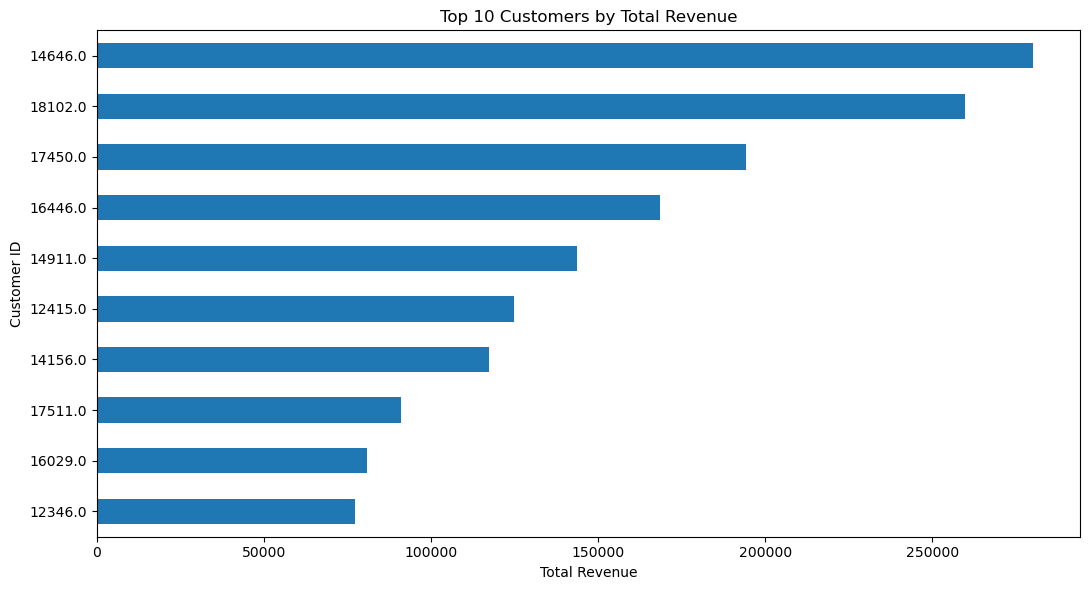

In [95]:
plt.figure(figsize=(11, 6))

top_customers['TotalRevenue'].sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Total Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

In [96]:
one_time = (customer_summary['TotalInvoices'] == 1).sum()
repeat = (customer_summary['TotalInvoices'] > 1).sum()

print("One-time customers:", one_time)
print("Repeat customers:", repeat)
print("Total customers:", len(customer_summary))

print("\nOne-time customer share: {:.2f}%".format(
    one_time / len(customer_summary) * 100
))
print("Repeat customer share: {:.2f}%".format(
    repeat / len(customer_summary) * 100
))

One-time customers: 1493
Repeat customers: 2845
Total customers: 4338

One-time customer share: 34.42%
Repeat customer share: 65.58%


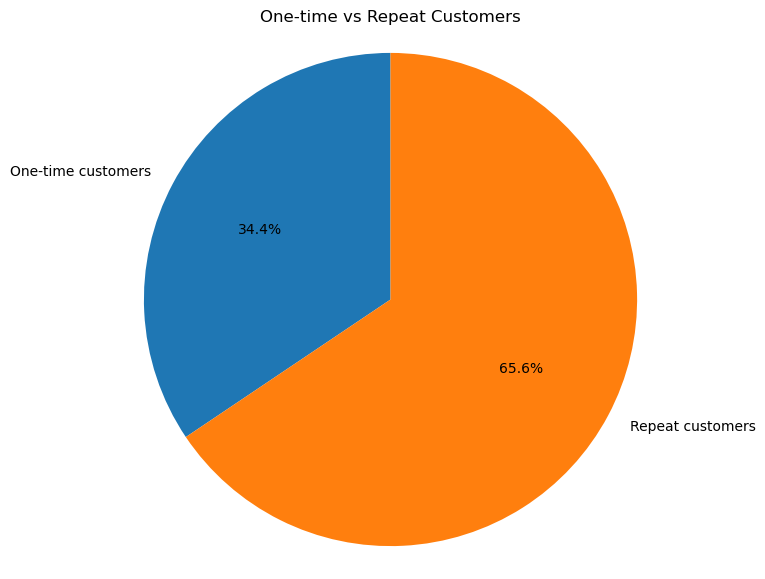

In [97]:
customer_types = pd.Series({
    'One-time customers': one_time,
    'Repeat customers': repeat
})

plt.figure(figsize=(7, 7))

plt.pie(
    customer_types,
    labels=customer_types.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('One-time vs Repeat Customers')
plt.axis('equal')
plt.show()

### 9.2 RFM Analysis and Customer Segmentation

RFM analysis begins

Recency (R): How recently did the customer make a purchase?
Frequency (F): How many distinct invoices did the customer place?
Monetary (M): How much total revenue did the customer generate?

In [99]:
reference_date = df_customer['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Latest transaction date:", df_customer['InvoiceDate'].max())
print("RFM reference date:", reference_date)

Latest transaction date: 2011-12-09 12:50:00
RFM reference date: 2011-12-10 12:50:00


In [100]:
rfm = (
    df_customer
    .groupby('CustomerID')
    .agg(
        Recency=('InvoiceDate', lambda x:
                 (reference_date - x.max()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('Revenue', 'sum')
    )
)

print(rfm.head())
print("\nRFM dataset shape:", rfm.shape)

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40

RFM dataset shape: (4338, 3)


In [101]:
print(rfm.describe().round(2))

       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00    1660.60
max     374.00     209.00  280206.02


In [102]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

print(rfm.head(10))

            Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
CustomerID                                                                   
12346.0         326          1  77183.60        1        1        5       115
12347.0           2          7   4310.00        5        5        5       555
12348.0          75          4   1797.24        2        4        4       244
12349.0          19          1   1757.55        4        1        4       414
12350.0         310          1    334.40        1        1        2       112
12352.0          36          8   2506.04        3        5        5       355
12353.0         204          1     89.00        1        1        1       111
12354.0         232          1   1079.40        1        1        4       114
12355.0         214          1    459.40        1        1        2       112
12356.0          23          3   2811.43        4        3        5       435


In [103]:
print("Recency score distribution:")
print(rfm['R_Score'].value_counts().sort_index())

print("\nFrequency score distribution:")
print(rfm['F_Score'].value_counts().sort_index())

print("\nMonetary score distribution:")
print(rfm['M_Score'].value_counts().sort_index())

Recency score distribution:
R_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

Frequency score distribution:
F_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

Monetary score distribution:
M_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64


In [104]:
rfm['Segment'] = np.where(
    (rfm['R_Score'] >= 4) &
    (rfm['F_Score'] >= 4) &
    (rfm['M_Score'] >= 4),
    'Champions',
    'Other Customers'
)

print(rfm['Segment'].value_counts())

Segment
Other Customers    3396
Champions           942
Name: count, dtype: int64


In [105]:
champions = (
    rfm[rfm['Segment'] == 'Champions']
    .sort_values('Monetary', ascending=False)
)

print("Top 10 Champions by revenue:")
print(
    champions[
        ['Recency', 'Frequency', 'Monetary',
         'R_Score', 'F_Score', 'M_Score']
    ].head(10).round(2)
)

Top 10 Champions by revenue:
            Recency  Frequency   Monetary  R_Score  F_Score  M_Score
CustomerID                                                          
14646.0           2         73  280206.02        5        5        5
18102.0           1         60  259657.30        5        5        5
17450.0           8         46  194390.79        5        5        5
14911.0           1        201  143711.17        5        5        5
12415.0          24         21  124914.53        4        5        5
14156.0          10         55  117210.08        5        5        5
17511.0           3         31   91062.38        5        5        5
16684.0           4         28   66653.56        5        5        5
14096.0           4         17   65164.79        5        5        5
13694.0           4         50   65039.62        5        5        5


<Axes: title={'center': 'Customer Segmentation using RFM'}, xlabel='Customer Segment', ylabel='Number of Customers'>

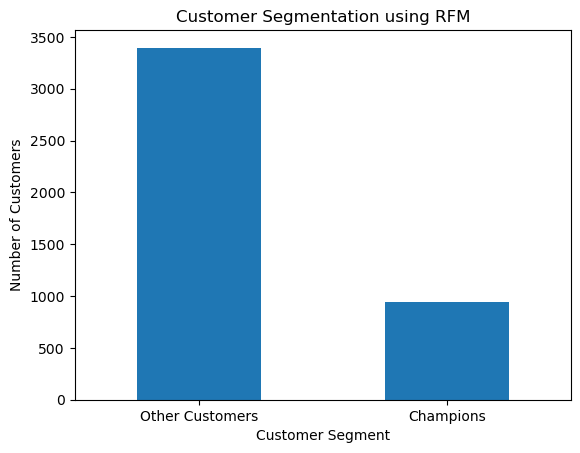

In [106]:
segment_counts = rfm['Segment'].value_counts()

segment_counts.plot(
    kind='bar',
    title='Customer Segmentation using RFM',
    xlabel='Customer Segment',
    ylabel='Number of Customers',
    rot=0
)

In [107]:
inactive_customers = rfm[rfm['R_Score'] <= 2]

print("Customers with low Recency scores:", len(inactive_customers))
print(
    "Percentage:",
    round(len(inactive_customers) / len(rfm) * 100, 2),
    "%"
)

Customers with low Recency scores: 1735
Percentage: 40.0 %


In [108]:
print("Revenue from low-Recency customers:",
      round(inactive_customers['Monetary'].sum(), 2))

print("Total customer revenue:",
      round(rfm['Monetary'].sum(), 2))

print("Share of customer revenue (%):",
      round(
          inactive_customers['Monetary'].sum()
          / rfm['Monetary'].sum() * 100,
          2
      ))

Revenue from low-Recency customers: 1347715.72
Total customer revenue: 8887208.89
Share of customer revenue (%): 15.16


In [109]:
segment_revenue = rfm.groupby('Segment')['Monetary'].sum()

print("Revenue by customer segment:")
print(segment_revenue.round(2))

print("\nRevenue share by segment (%):")
print(
    (segment_revenue / rfm['Monetary'].sum() * 100).round(2)
)

Revenue by customer segment:
Segment
Champions          5737952.12
Other Customers    3149256.77
Name: Monetary, dtype: float64

Revenue share by segment (%):
Segment
Champions          64.56
Other Customers    35.44
Name: Monetary, dtype: float64


<Axes: title={'center': 'Revenue Contribution by Customer Segment'}, xlabel='Customer Segment', ylabel='Total Revenue (£)'>

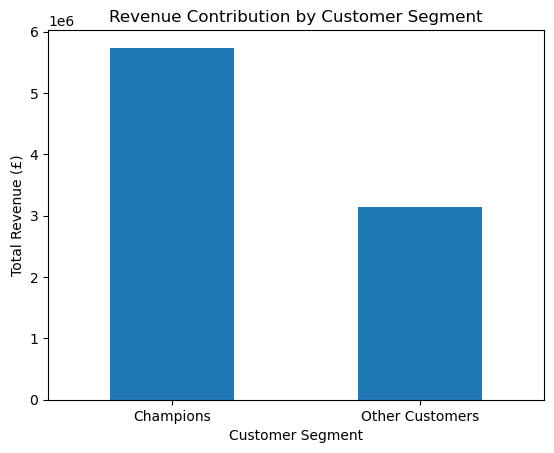

In [110]:
segment_revenue.plot(
    kind='bar',
    title='Revenue Contribution by Customer Segment',
    xlabel='Customer Segment',
    ylabel='Total Revenue (£)',
    rot=0
)

### 9.3 Monthly Invoice and Average Invoice Revenue Trends

In [111]:
monthly_orders = (
    df_sales.set_index('InvoiceDate')
    .resample('MS')['InvoiceNo']
    .nunique()
)

print("Monthly number of invoices:")
print(monthly_orders)

Monthly number of invoices:
InvoiceDate
2010-12-01    1559
2011-01-01    1086
2011-02-01    1100
2011-03-01    1454
2011-04-01    1246
2011-05-01    1681
2011-06-01    1533
2011-07-01    1475
2011-08-01    1360
2011-09-01    1837
2011-10-01    2040
2011-11-01    2769
2011-12-01     819
Freq: MS, Name: InvoiceNo, dtype: int64


<Axes: title={'center': 'Monthly Invoice Trend'}, xlabel='Month', ylabel='Number of Invoices'>

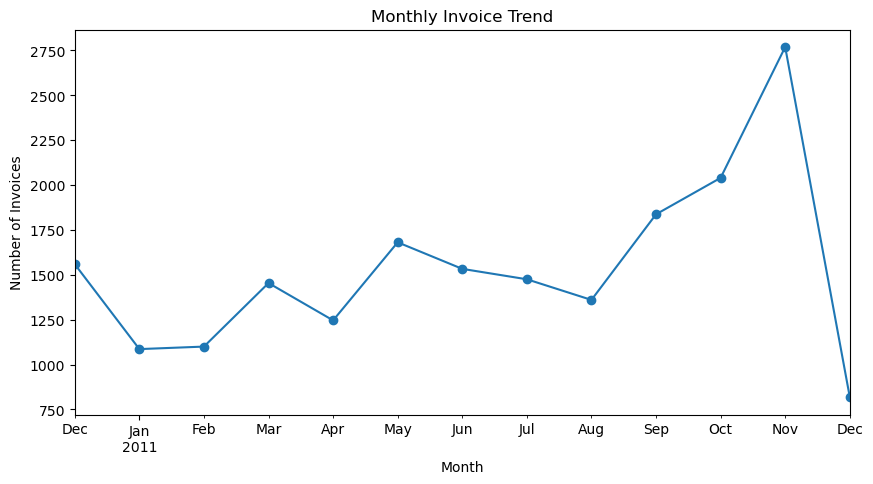

In [112]:
monthly_orders.plot(
    kind='line',
    marker='o',
    title='Monthly Invoice Trend',
    xlabel='Month',
    ylabel='Number of Invoices',
    figsize=(10, 5)
)

In [113]:
monthly_avg_order = (
    df_sales.groupby(df_sales['InvoiceDate'].dt.to_period('M'))
    .agg(
        TotalRevenue=('Revenue', 'sum'),
        TotalInvoices=('InvoiceNo', 'nunique')
    )
)

monthly_avg_order['AvgRevenuePerInvoice'] = (
    monthly_avg_order['TotalRevenue'] /
    monthly_avg_order['TotalInvoices']
)

print(monthly_avg_order.round(2))

             TotalRevenue  TotalInvoices  AvgRevenuePerInvoice
InvoiceDate                                                   
2010-12         821452.73           1559                526.91
2011-01         689811.61           1086                635.19
2011-02         522545.56           1100                475.04
2011-03         716215.26           1454                492.58
2011-04         536968.49           1246                430.95
2011-05         769296.61           1681                457.64
2011-06         760547.01           1533                496.12
2011-07         718076.12           1475                486.83
2011-08         746779.32           1360                549.10
2011-09        1056435.19           1837                575.09
2011-10        1151263.73           2040                564.34
2011-11        1503866.78           2769                543.11
2011-12         637790.33            819                778.74


### 9.4 Special Transaction Entries and Product-Analysis Dataset

In [114]:
special_keywords = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'MANUAL',
    'CARRIAGE',
    'BANK CHARGES',
    'AMAZON FEE',
    'SAMPLES'
]

for keyword in special_keywords:
    mask = df_sales['Description'].str.contains(
        keyword, case=False, na=False
    )

    print(
        f"{keyword}:",
        "Rows =", mask.sum(),
        "| Revenue = £",
        round(df_sales.loc[mask, 'Revenue'].sum(), 2)
    )

POSTAGE: Rows = 1832 | Revenue = £ 284350.65
DOTCOM POSTAGE: Rows = 706 | Revenue = £ 206248.77
MANUAL: Rows = 317 | Revenue = £ 77752.82
CARRIAGE: Rows = 314 | Revenue = £ 9609.14
BANK CHARGES: Rows = 12 | Revenue = £ 165.0
AMAZON FEE: Rows = 2 | Revenue = £ 13761.09
SAMPLES: Rows = 2 | Revenue = £ 63.05


In [115]:
special_keywords = (
    'POSTAGE|MANUAL|CARRIAGE|BANK CHARGES|'
    'AMAZON FEE|SAMPLES'
)

special_rows = df_sales[
    df_sales['Description'].str.contains(
        special_keywords,
        case=False,
        na=False,
        regex=True
    )
]

print(
    special_rows['Description']
    .value_counts()
    .head(20)
)

Description
POSTAGE                         1126
DOTCOM POSTAGE                   706
Manual                           317
CARRIAGE                         141
Next Day Carriage                 79
FRENCH CARRIAGE LANTERN           59
BLACK BAROQUE CARRIAGE CLOCK      35
Bank Charges                      12
AMAZON FEE                         2
SAMPLES                            2
Name: count, dtype: int64


In [116]:
non_product_descriptions = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'CARRIAGE',
    'Next Day Carriage',
    'Bank Charges',
    'AMAZON FEE'
]

df_product_sales = df_sales[
    ~df_sales['Description'].isin(non_product_descriptions)
].copy()

print("Original sales rows:", len(df_sales))
print("Product-sales rows:", len(df_product_sales))

print(
    "Revenue retained (£):",
    round(df_product_sales['Revenue'].sum(), 2)
)

print(
    "Revenue in original dataset (£):",
    round(df_sales['Revenue'].sum(), 2)
)

Original sales rows: 524877
Product-sales rows: 522811
Revenue retained (£): 10324521.0
Revenue in original dataset (£): 10631048.74


In [117]:
excluded_rows = df_sales[
    ~df_sales['Description'].isin(non_product_descriptions)
]

# Rows excluded by the filter
excluded_rows = df_sales[
    df_sales['Description'].isin(non_product_descriptions)
]

print(excluded_rows.groupby('Description').agg(
    Rows=('Revenue', 'size'),
    Revenue=('Revenue', 'sum')
).round(2))

                   Rows    Revenue
Description                       
AMAZON FEE            2   13761.09
Bank Charges         12     165.00
CARRIAGE            141    7051.00
DOTCOM POSTAGE      706  206248.77
Next Day Carriage    79    1200.00
POSTAGE            1126   78101.88


In [118]:
df_sales[
    df_sales['Description'].isin(['Manual', 'SAMPLES'])
][
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'Revenue', 'Country']
].head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,Country
2239,536569,M,Manual,1,1.25,1.25,United Kingdom
2250,536569,M,Manual,1,18.95,18.95,United Kingdom
5684,536865,M,Manual,1,2.55,2.55,United Kingdom
6798,536981,M,Manual,2,0.85,1.70,United Kingdom
7976,537077,M,Manual,12,0.42,5.04,United Kingdom
8530,537137,M,Manual,36,0.85,30.60,United Kingdom
8587,537140,M,Manual,1,0.42,0.42,United Kingdom
8588,537140,M,Manual,1,0.85,0.85,United Kingdom
9326,537199,M,Manual,1,0.65,0.65,United Kingdom
9575,537208,M,Manual,4,0.85,3.40,United Kingdom


In [119]:
df_sales[
    df_sales['Description'].isin(['Manual', 'SAMPLES'])
].groupby('Description').agg(
    Rows=('InvoiceNo', 'size'),
    UniqueInvoices=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('Revenue', 'sum')
).round(2)

,Rows,UniqueInvoices,TotalQuantity,TotalRevenue
Description,,,,
Manual,317,290,6985,77752.82
SAMPLES,2,2,2,63.05


In [120]:
non_product_descriptions = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'CARRIAGE',
    'Next Day Carriage',
    'Bank Charges',
    'AMAZON FEE',
    'Manual',
    'SAMPLES'
]

df_product_sales = df_sales[
    ~df_sales['Description'].isin(non_product_descriptions)
].copy()

print("Original rows:", len(df_sales))
print("Product-analysis rows:", len(df_product_sales))
print("Original revenue (£):", round(df_sales['Revenue'].sum(), 2))
print("Product-analysis revenue (£):", round(df_product_sales['Revenue'].sum(), 2))

Original rows: 524877
Product-analysis rows: 522492
Original revenue (£): 10631048.74
Product-analysis revenue (£): 10246705.13


In [121]:
df_product_sales[
    df_product_sales['Description'].isin(non_product_descriptions)
]['Description'].value_counts()

Series([], Name: count, dtype: int64)

### 9.5 Product Rankings After Special-Entry Filtering

In [122]:
top_products_clean = (
    df_product_sales.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_clean.round(2))

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64


In [123]:
top_quantity_clean = (
    df_product_sales.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_quantity_clean)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


<Axes: title={'center': 'Top 10 Products by Quantity Sold'}, xlabel='Total Quantity', ylabel='Product'>

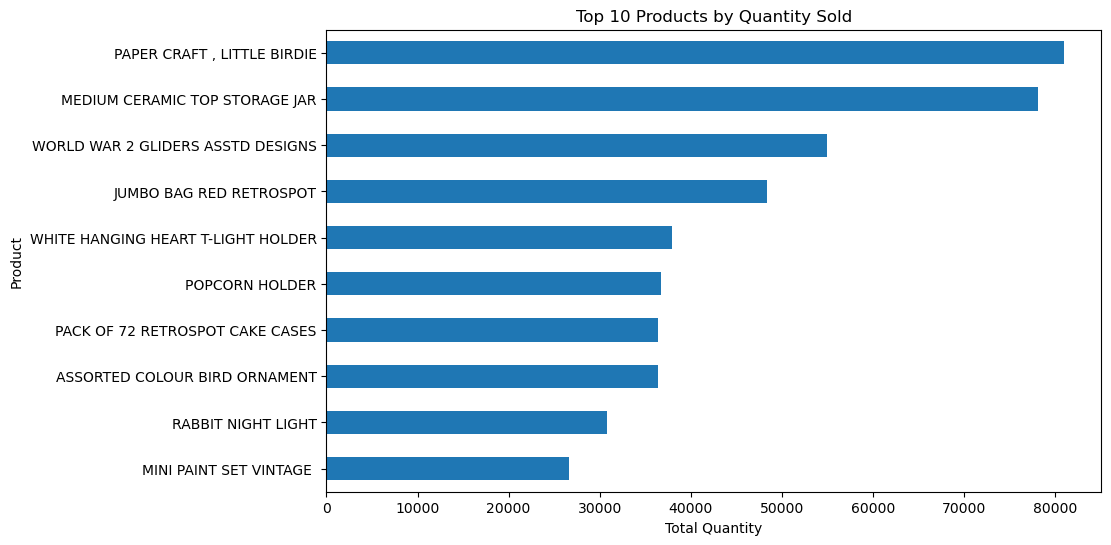

In [124]:
top_quantity_clean.sort_values().plot(
    kind='barh',
    title='Top 10 Products by Quantity Sold',
    xlabel='Total Quantity',
    ylabel='Product',
    figsize=(10, 6)
)

## 10. Export Data for Power BI

In [ ]:

from pathlib import Path

# Create a folder for Power BI export files
export_dir = Path("powerbi_exports")
export_dir.mkdir(exist_ok=True)

# Export existing datasets without their pandas indexes
df_sales.to_csv(
    export_dir / "sales_transactions.csv",
    index=False
)

df_product_sales.to_csv(
    export_dir / "product_sales.csv",
    index=False
)

rfm.reset_index().to_csv(
    export_dir / "customer_rfm.csv",
    index=False
)

print("Power BI export files created:")
for file in export_dir.glob("*.csv"):
    print(file.resolve())
